# Lesson 22 - "Other" is always a class: the mel bands, the engineered features, and both together

**The rule from now on: whatever classes we keep, the ship types we don't name stay in the data as one more class,
"other".** A hydrophone in the water hears every ship. Lessons 13-20 trained and tested on six classes only, so a
sailing yacht or a passenger ferry could only ever be called one of the six, and the scores never counted that
mistake. Lesson 21 showed what "other" costs; this lesson and the next two redo the main experiments with it.

| Class | Ships | Clips |
|---|---|---|
| background | 802 recording days | 3,600 |
| cargo | 2,522 | 3,601 |
| fishing | 238 | 3,601 |
| pleasure craft | 406 | 3,600 |
| tanker | 233 | 3,601 |
| tug | 297 | 3,601 |
| **other** = sailing 212 + the dataset's "other" 169 + passenger ship 110 + rescue 23 + dredger 6 + pilot vessel 2 | 522 | 21,604 |

"Other" has six times the clips of a class, so the training weights give it the same total as each named class;
inside it every type counts the same, and inside a type every ship (lesson 20). Folds: lesson 13's for the six
classes (unchanged), and five folds by ship for the "other" ships (lesson 21), so every ship is tested once, never
heard in training. Settings are chosen on the validation fold; the test fold is scored once.

**Questions of this lesson**

1. Logistic regression and gradient boosting on the mel bands *before* any MFCC (mean and spread of each band).
   Lesson 13 did this without "other": 56.9 / 58.4 %.
2. The 144 engineered features together with the mel-band mean, spread and percentiles, in one model. Never tried
   before: lesson 13 compared the two sets side by side, lesson 03's "rich" set had percentiles but no engineered
   features.

```
python src/with_other.py features    # mel-band statistics of all 43,208 clips (2 min)
python src/with_other.py main        # 5 sets x 2 models x 5 folds -> runs/with_other/main.jsonl (CPU)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import with_other as W

OUT = W.OUT_DIR
res = pd.DataFrame(W.Log(OUT / "main.jsonl").rows)
names = list(W.GROUPINGS[W.MAIN])
pd.set_option("display.width", 170)
MODEL_COLORS = {"gradient boosting": "#2a78d6", "logistic regression": "#eb6834"}


def pm(g, col):
    """mean ± spread over the five test folds, in %"""
    return (100 * g[col].mean()).round(1).astype(str) + " ± " + (100 * g[col].std()).round(1).astype(str)

## 1. The five feature sets

| Set | Numbers | What it is |
|---|---|---|
| mel mean + spread | 257 | each of the 128 mel bands (10 Hz-16 kHz): its average level and how much it varies over the 5 s, plus the overall average. The spectrogram *before* MFCC |
| mel mean + spread + percentiles | 641 | + the 10th, 50th and 90th percentile of every band (quietest moments, typical level, loudest moments) |
| engineered | 144 | lesson 13's seven groups: MFCC 1-19, 1/3-octave levels, level changes, spectral shape, loudness, tonal lines, DEMON |
| engineered + mel mean + spread | 401 | both in one model |
| engineered + mel mean + spread + percentiles | 785 | everything |

In [2]:
SIZE_ORDER = [257, 641, 144, 401, 785]                     # the order of the table in section 1
order = sorted(res.features.unique(), key=lambda s: SIZE_ORDER.index(int(s.rsplit("(", 1)[1].rstrip(")"))))
res = res.assign(_set=res.features.map(order.index), _model=res.model.map({"logistic regression": 0, "gradient boosting": 1}))
res = res.sort_values(["_set", "_model", "fold"]).drop(columns=["_set", "_model"])
g = res.groupby(["features", "model"], sort=False)
table = pd.DataFrame({"numbers": g.n_features.first(), "per clip": pm(g, "balanced_accuracy"),
                      "per ship": pm(g, "per_ship_balanced_accuracy"),
                      "other recall": (100 * g.per_class_recall.apply(lambda s: np.mean([d["other"] for d in s]))).round(1),
                      "validation": (100 * g.val_balanced_accuracy.mean()).round(1),
                      "final fit (s)": g.seconds_fit.mean().round(0),
                      "predict (µs/clip)": g.predict_us_per_clip.mean().round(1)})
print("6 classes + other, balanced accuracy on the test folds (mean ± spread of 5), chance 14.3 %")
print(table.to_string())

6 classes + other, balanced accuracy on the test folds (mean ± spread of 5), chance 14.3 %
                                                                        numbers    per clip    per ship  other recall  validation  final fit (s)  predict (µs/clip)
features                                           model                                                                                                           
mel mean + spread (257)                            logistic regression      257  48.1 ± 1.4  55.3 ± 1.8          13.9        47.5            3.0                1.2
                                                   gradient boosting        257  50.3 ± 1.5  57.3 ± 1.8          14.8        49.7          136.0               70.6
mel mean + spread + percentiles (641)              logistic regression      641  48.3 ± 1.3  54.7 ± 1.8          14.7        47.3           22.0                5.5
                                                   gradient boosting        641  50.5 ± 0

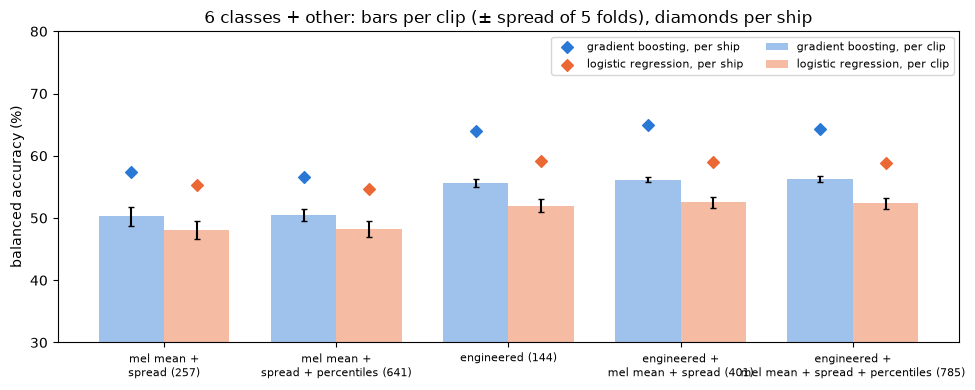

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(order))
for i, (model, color) in enumerate(MODEL_COLORS.items()):
    sub = res[res.model == model].groupby("features").per_ship_balanced_accuracy
    clip = res[res.model == model].groupby("features").balanced_accuracy
    ax.bar(x + (i - 0.5) * 0.38, [100 * clip.mean()[s] for s in order], 0.38, color=color, alpha=0.45,
           yerr=[100 * clip.std()[s] for s in order], capsize=2, label=f"{model}, per clip")
    ax.scatter(x + (i - 0.5) * 0.38, [100 * sub.mean()[s] for s in order], color=color, marker="D", zorder=3,
               label=f"{model}, per ship")
ax.set_xticks(x, [s.replace(" + ", " +\n", 1) for s in order], fontsize=8)
ax.set_ylabel("balanced accuracy (%)"); ax.set_ylim(30, 80); ax.axhline(100 / 7, color="grey", ls="--", lw=1)
ax.legend(fontsize=8, ncol=2); ax.set_title("6 classes + other: bars per clip (± spread of 5 folds), diamonds per ship")
plt.tight_layout(); plt.show()

- **Question 1, the mel bands before any MFCC:** gradient boosting 50.3 ± 1.5 %, logistic regression 48.1 ± 1.4 % per
  clip (57.3 / 55.3 % per ship). Their 10th / 50th / 90th percentiles add nothing (50.5 / 48.3 %), with 2.5 times the
  numbers and twice the fitting time.
- **Question 2, the engineered features and the mel statistics in one model:** the best set. Engineered + mel mean +
  spread (401 numbers): **56.2 ± 0.4 % per clip, 65.0 ± 2.6 % per ship** with gradient boosting, +0.6 and +1.1 points
  over the 144 engineered numbers alone (55.6 / 63.9 %), and also better on validation (55.1 against 54.5 %). Adding
  the percentiles too (785 numbers) gives no more (56.3 / 64.4 %) for almost 4 times the fitting time (338 against
  90 s).
- **The engineered features matter more with "other":** +5.3 points over the mel bands (gradient boosting; +3.5 in
  lesson 13), and they recognise "other" twice as often (32 % against 15 %).
- **Gradient boosting beats logistic regression by 2-4 points everywhere.** Logistic regression hardly ever answers
  "other" (14-18 %).
- **Set used from lesson 24 on: engineered + mel mean + spread (401).** It has the best mean validation score; the
  785-number set is within half a point but has twice the numbers.

## 2. Which classes, and where "other" goes

recall per class, per clip (%), mean of 5 folds:
                                                                        background  cargo  fishing  pleasurecraft  tanker   tug  other
features                                           model                                                                              
mel mean + spread (257)                            logistic regression        80.8   56.2     35.2           50.3    53.8  46.5   13.9
                                                   gradient boosting          83.8   59.1     36.4           53.9    53.0  50.7   14.8
mel mean + spread + percentiles (641)              logistic regression        81.1   56.6     34.2           51.4    53.6  46.2   14.7
                                                   gradient boosting          84.1   59.3     36.1           53.9    52.4  51.9   15.6
engineered (144)                                   logistic regression        82.6   58.5     39.4           53.8    57.9  54.3   17.5
      

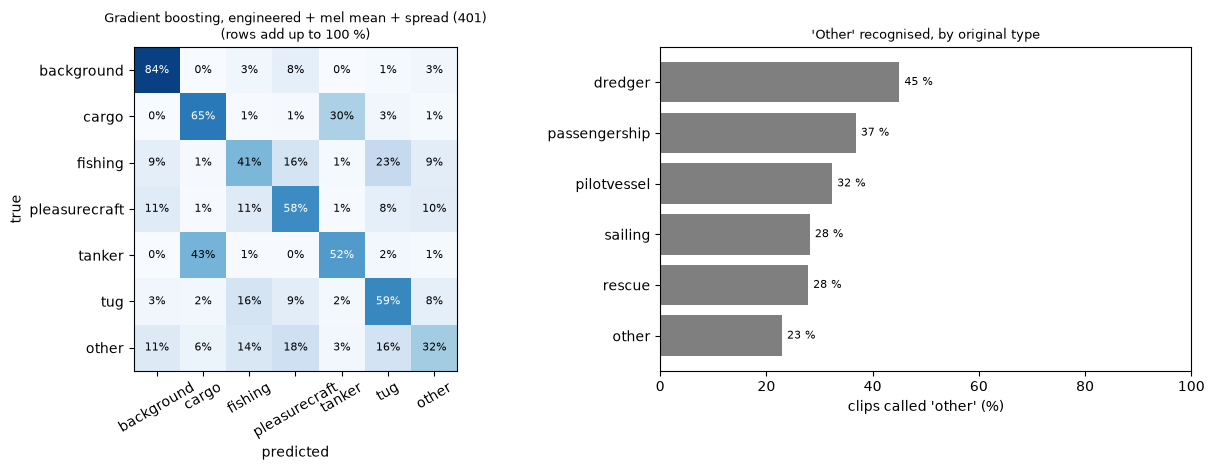

In [4]:
best = (res[res.model == "gradient boosting"].groupby("features").val_balanced_accuracy.mean().idxmax())
rec = pd.DataFrame([dict(d) for d in res.per_class_recall]).assign(features=res.features.values, model=res.model.values)
print("recall per class, per clip (%), mean of 5 folds:")
print((100 * rec.groupby(["features", "model"], sort=False).mean()).round(1).to_string())

preds = pd.read_parquet(OUT / "main_predictions.parquet")
p = preds[(preds.features == best) & (preds.model == "gradient boosting")]
probs = p[[f"p_{n}" for n in names]].to_numpy()
cm = confusion_matrix(p.y, probs.argmax(1), labels=range(len(names)), normalize="true")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].imshow(cm, cmap="Blues", vmin=0, vmax=0.9)
for i in range(len(names)):
    for j in range(len(names)):
        ax[0].text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.5 else "black")
ax[0].set_xticks(range(len(names)), names, rotation=30); ax[0].set_yticks(range(len(names)), names)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title(f"Gradient boosting, {best}\n(rows add up to 100 %)", fontsize=9)
oth = p[p.label.isin(W.LEFT_OUT)]
by_type = (100 * pd.Series(probs[p.label.isin(W.LEFT_OUT).to_numpy()].argmax(1) == names.index("other"))
           .groupby(oth.label.to_numpy()).mean()).sort_values()
ax[1].barh(by_type.index, by_type.values, color="#7f7f7f")
for i, v in enumerate(by_type.values):
    ax[1].text(v + 1, i, f"{v:.0f} %", va="center", fontsize=8)
ax[1].set_xlim(0, 100); ax[1].set_xlabel("clips called 'other' (%)"); ax[1].set_title("'Other' recognised, by original type", fontsize=9)
plt.tight_layout(); plt.show()

- **"Other" is the hardest class: 32 % of its clips are recognised.** The rest is spread over the small boats and
  background (pleasure craft 18 %, tug 16 %, fishing 14 %, background 11 %); it has no sound of its own, as it mixes
  yachts, ferries, rescue boats and dredgers.
- **It also takes clips from the small boats:** 10 % of pleasure craft, 9 % of fishing boats and 8 % of tugs are
  called "other". Big ships are not affected: cargo and tankers go to "other" 1 % of the time, and still mostly to each
  other (30 % and 43 %, as in lesson 13).
- **By original type** (right panel): dredgers 45 %, passenger ships 37 %, pilot vessels 32 %, sailing and rescue
  28 %, the dataset's own "other" 23 %. Dredger (6 ships), pilot vessel (2) and rescue (23) rest on very few ships.

## 3. Against the lessons without "other"

In [5]:
old = pd.DataFrame(json.loads((W.RUNS_DIR / "six_classes" / "results.json").read_text())["results"])
old_g = old.groupby(["features", "model"]).balanced_accuracy.mean()
pairs = {("mel mean + spread (257)", "gradient boosting"): ("simple (no MFCC)", "gradient boosting"),
         ("mel mean + spread (257)", "logistic regression"): ("simple (no MFCC)", "logistic regression"),
         ("engineered (144)", "gradient boosting"): ("engineered", "gradient boosting"),
         ("engineered (144)", "logistic regression"): ("engineered", "logistic regression")}
new_g = res.groupby(["features", "model"]).balanced_accuracy.mean()
print(pd.DataFrame([{"set": a, "model": b, "6 classes (lesson 13)": round(100 * old_g[pairs[(a, b)]], 1),
                     "6 classes + other": round(100 * new_g[(a, b)], 1),
                     "cost of 'other' (points)": round(100 * (new_g[(a, b)] - old_g[pairs[(a, b)]]), 1)}
                    for a, b in pairs]).to_string(index=False))

                    set               model  6 classes (lesson 13)  6 classes + other  cost of 'other' (points)
mel mean + spread (257)   gradient boosting                   58.4               50.3                      -8.2
mel mean + spread (257) logistic regression                   56.9               48.1                      -8.8
       engineered (144)   gradient boosting                   61.9               55.6                      -6.2
       engineered (144) logistic regression                   60.8               52.0                      -8.8


- **"Other" costs 6-9 points per clip.** Two reasons: chance falls from 16.7 % to 14.3 %, and the new class itself is
  recognised only 32 % of the time; in balanced accuracy it counts like any other class. The six named classes lose
  about 2 points on top (gradient boosting, engineered + mel: their mean recall is 60.1 % against 61.9 % in lesson
  13), because "other" takes some of their clips.
- These are the honest numbers for a hydrophone that hears every ship. Every later lesson keeps "other".

## 4. What it means

| 6 classes + other, 5 test folds | Per clip | Per ship |
|---|---|---|
| mel mean + spread, logistic regression (question 1) | 48.1 % | 55.3 % |
| mel mean + spread, gradient boosting (question 1) | 50.3 % | 57.3 % |
| engineered (144), gradient boosting | 55.6 % | 63.9 % |
| **engineered + mel mean + spread (401), gradient boosting (question 2)** | **56.2 %** | **65.0 %** |
| + percentiles (785), gradient boosting | 56.3 % | 64.4 % |

- Keeping "other" lowers every number: the best six-class result per clip falls from 61.9 % to 56.2 %.
- Combining the engineered features with the mel-band statistics helps a little; the percentiles don't.
- The weak spots are "other" (32 %) and the small boats (fishing 42 %). Lesson 23 looks at which feature sets are
  worth their cost, lesson 24 at merging classes with "other" kept.